# Tugas Latihan Mandiri — Pertemuan 9: Perangkat Keras Embedded & Hardware Abstraction

**Mata Kuliah:** Sistem Tertanam dan Internet of Things (IoT)


Kelompok 4:
1. Hanifah Salsabila Zuheri - 2411513016
2. Muhammad Yusuf - 2411512010
3. Alif Ilham Permata - 2411511012



1. Pada Hands-On 1, buat skenario baru (mis. "Gateway edge-AI untuk pemrosesan citra") dengan bobot kriteria berbeda, dan analisis apakah rekomendasi platform berubah.

In [ ]:
kriteria = ['Efisiensi Daya', 'Performa Komputasi', 'Biaya Rendah',
            'Kemudahan Pengembangan', 'Konektivitas Bawaan']

# Skala 1 (buruk) - 5 (sangat baik)
skor_platform = {
    'STM32 (Blue Pill)': [5, 2, 5, 2, 1],
    'ESP32':             [4, 3, 4, 4, 5],
    'Raspberry Pi 4':    [1, 5, 2, 4, 5],
}

skenario = {
    'A. Sensor node baterai': {
        'Efisiensi Daya': 0.35, 'Performa Komputasi': 0.15, 'Biaya Rendah': 0.20,
        'Kemudahan Pengembangan': 0.15, 'Konektivitas Bawaan': 0.15},
    'B. Gateway edge-AI citra': {
        'Efisiensi Daya': 0.05, 'Performa Komputasi': 0.45, 'Biaya Rendah': 0.10,
        'Kemudahan Pengembangan': 0.15, 'Konektivitas Bawaan': 0.25},
}

def hitung_skor(bobot):
    w = np.array([bobot[k] for k in kriteria], dtype=float)
    w = w / w.sum()                                   # normalisasi
    return {p: float(np.dot(s, w)) for p, s in skor_platform.items()}

print("Bobot tiap skenario:")
print(pd.DataFrame(skenario).to_string())

baris = []
for nama, b in skenario.items():
    for p, v in hitung_skor(b).items():
        baris.append({'Skenario': nama, 'Platform': p, 'Skor': round(v, 2)})
df_skor = pd.DataFrame(baris)
tabel = df_skor.pivot(index='Platform', columns='Skenario', values='Skor')

print("\nSkor akhir (0-5):")
print(tabel.to_string())
print()
for nama in skenario:
    print(f"Rekomendasi {nama:<26}: {tabel[nama].idxmax()} (skor {tabel[nama].max():.2f})")

Bobot tiap skenario:
                        A. Sensor node baterai  B. Gateway edge-AI citra
Efisiensi Daya                            0.35                      0.05
Performa Komputasi                        0.15                      0.45
Biaya Rendah                              0.20                      0.10
Kemudahan Pengembangan                    0.15                      0.15
Konektivitas Bawaan                       0.15                      0.25

Skor akhir (0-5):
Skenario           A. Sensor node baterai  B. Gateway edge-AI citra
Platform                                                           
ESP32                                4.00                      3.80
Raspberry Pi 4                       2.85                      4.35
STM32 (Blue Pill)                    3.50                      2.20

Rekomendasi A. Sensor node baterai    : ESP32 (skor 4.00)
Rekomendasi B. Gateway edge-AI citra  : Raspberry Pi 4 (skor 4.35)


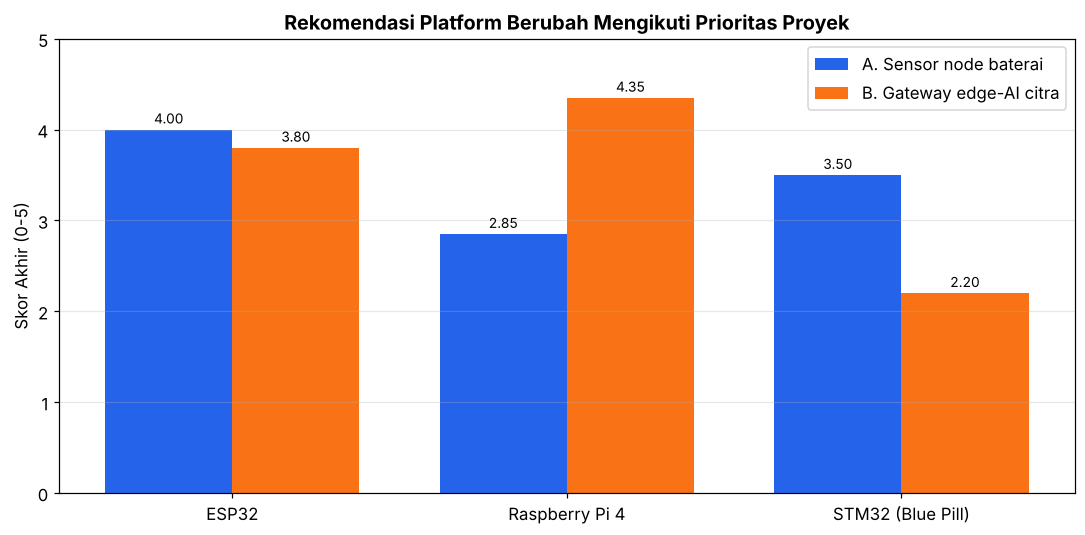

In [ ]:
# Visualisasi: perbandingan skor akhir per skenario
platforms = list(tabel.index)
x = np.arange(len(platforms))
lebar = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
for i, nama in enumerate(skenario):
    bars = ax.bar(x + (i - 0.5) * lebar, tabel[nama].values, lebar, label=nama,
                  color=['#2563eb', '#f97316'][i])
    for bar, v in zip(bars, tabel[nama].values):
        ax.annotate(f'{v:.2f}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    textcoords='offset points', xytext=(0, 4), ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(platforms)
ax.set_ylim(0, 5); ax.set_ylabel('Skor Akhir (0-5)')
ax.set_title('Rekomendasi Platform Berubah Mengikuti Prioritas Proyek', fontsize=13, fontweight='bold')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

Raspberry Pi 4 mengalahkan ESP32 mulai bobot performa komputasi >= 0.47
Bobot performa Skenario A = 0.15, Skenario B = 0.45


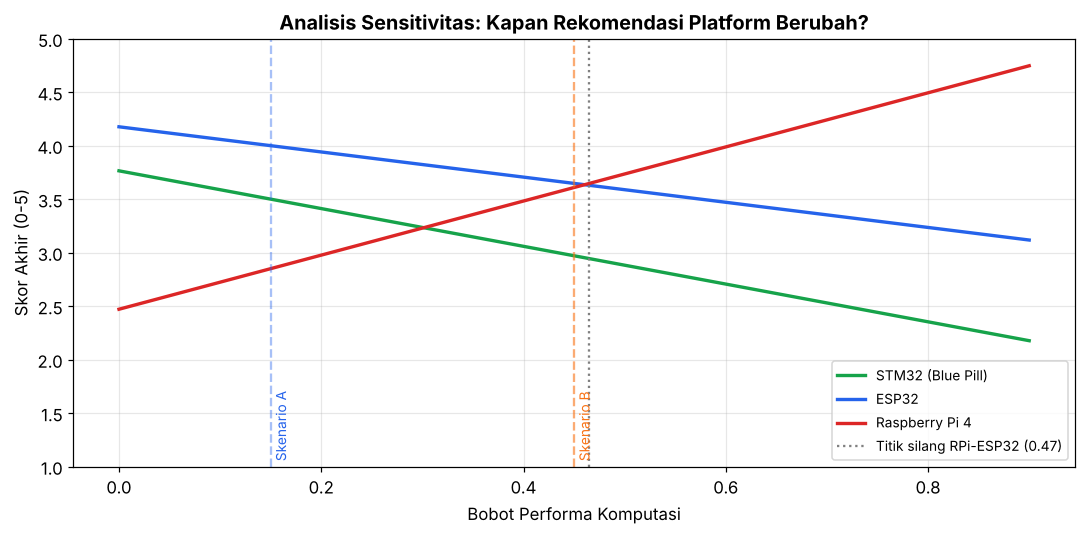

In [ ]:
# Analisis sensitivitas: geser bobot 'Performa Komputasi' dari 0 s.d. 0.9,
# bobot kriteria lain dibagi proporsional mengikuti Skenario A.
dasar = skenario['A. Sensor node baterai']
lain = {k: v for k, v in dasar.items() if k != 'Performa Komputasi'}
total_lain = sum(lain.values())

w_perf = np.linspace(0, 0.9, 181)
hasil_sweep = {p: [] for p in skor_platform}
for w in w_perf:
    b = {k: v / total_lain * (1 - w) for k, v in lain.items()}
    b['Performa Komputasi'] = w
    for p, v in hitung_skor(b).items():
        hasil_sweep[p].append(v)

def titik_silang(p_atas, p_bawah):
    selisih = np.array(hasil_sweep[p_atas]) - np.array(hasil_sweep[p_bawah])
    idx = np.argmax(selisih > 0)
    return w_perf[idx] if selisih.max() > 0 else None

w_rpi_esp = titik_silang('Raspberry Pi 4', 'ESP32')
print(f"Raspberry Pi 4 mengalahkan ESP32 mulai bobot performa komputasi >= {w_rpi_esp:.2f}")
print(f"Bobot performa Skenario A = {dasar['Performa Komputasi']:.2f}, Skenario B = {skenario['B. Gateway edge-AI citra']['Performa Komputasi']:.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
warna = {'STM32 (Blue Pill)': '#16a34a', 'ESP32': '#2563eb', 'Raspberry Pi 4': '#dc2626'}
for p, nilai in hasil_sweep.items():
    ax.plot(w_perf, nilai, label=p, color=warna[p], linewidth=2.2)
ax.axvline(w_rpi_esp, color='gray', linestyle=':', label=f'Titik silang RPi-ESP32 ({w_rpi_esp:.2f})')
ax.axvline(0.15, color='#2563eb', linestyle='--', alpha=0.4)
ax.axvline(0.45, color='#f97316', linestyle='--', alpha=0.6)
ax.text(0.152, 1.05, 'Skenario A', fontsize=9, color='#2563eb', rotation=90, va='bottom')
ax.text(0.452, 1.05, 'Skenario B', fontsize=9, color='#f97316', rotation=90, va='bottom')
ax.set_xlabel('Bobot Performa Komputasi'); ax.set_ylabel('Skor Akhir (0-5)')
ax.set_title('Analisis Sensitivitas: Kapan Rekomendasi Platform Berubah?', fontsize=13, fontweight='bold')
ax.set_ylim(1, 5); ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Analisis Soal 1

**Hasil:**

| Platform | Skenario A: sensor node baterai | Skenario B: gateway edge-AI citra |
|---|---|---|
| ESP32 | **4.00** | 3.80 |
| Raspberry Pi 4 | 2.85 | **4.35** |
| STM32 (Blue Pill) | 3.50 | 2.20 |

**Apakah rekomendasi berubah? Ya.** Pada skenario A rekomendasinya ESP32, sedangkan pada skenario B rekomendasinya berpindah ke Raspberry Pi 4. Matriks skornya sama persis, jadi perubahan ini murni berasal dari perubahan bobot.

**Mengapa berubah:**
- Pada skenario B bobot *Efisiensi Daya* turun dari 0.35 menjadi 0.05, sedangkan bobot *Performa Komputasi* naik dari 0.15 menjadi 0.45 dan *Konektivitas Bawaan* naik menjadi 0.25. Pemrosesan citra (inferensi model deteksi objek) butuh CPU/RAM besar dan Linux penuh, dan kebutuhan itu hanya dipenuhi Raspberry Pi (skor performa 5).
- Kelemahan Raspberry Pi di efisiensi daya (skor 1) dan biaya (skor 2) menjadi kurang berpengaruh karena bobotnya dikecilkan.
- STM32 anjlok ke 2.20 karena kekuatannya (daya rendah dan biaya murah) kini berbobot kecil, sementara kelemahannya (performa rendah, tanpa radio bawaan) berbobot besar.
- ESP32 turun hanya sedikit (4.00 menjadi 3.80) dan tetap kompetitif karena skornya merata di semua kriteria.





2. Pada Hands-On 4, tambahkan resolusi ADC 16-bit ke dalam simulasi dan analisis peningkatan presisi dibanding 12-bit — apakah peningkatannya signifikan untuk aplikasi sensor suhu?

In [ ]:
def kuantisasi_adc(sinyal_analog, bit_resolusi, v_ref=3.3):
    level = 2 ** bit_resolusi
    langkah = v_ref / level
    sinyal_terkuantisasi = np.round(sinyal_analog / langkah) * langkah
    return sinyal_terkuantisasi, langkah

# Sinyal analog: sinus 0-3.3 V, 2 Hz (sama seperti Hands-On 4)
t = np.linspace(0, 1, 200000)
sinyal_asli = 1.65 + 1.65 * np.sin(2 * np.pi * 2 * t)

resolusi_list = [8, 10, 12, 16]
baris, hasil_adc = [], {}
for bit in resolusi_list:
    sq, langkah = kuantisasi_adc(sinyal_asli, bit)
    rmse = np.sqrt(np.mean((sinyal_asli - sq) ** 2))
    hasil_adc[bit] = sq
    baris.append({'Resolusi': f'{bit}-bit', 'Jumlah level': 2 ** bit,
                  'Langkah (mV)': round(langkah * 1000, 4),
                  'RMSE (mV)': round(rmse * 1000, 4),
                  'Teori LSB/sqrt(12) (mV)': round(langkah * 1000 / np.sqrt(12), 4)})
df_adc = pd.DataFrame(baris)
print(df_adc.to_string(index=False))

r12 = df_adc.loc[df_adc['Resolusi'] == '12-bit', 'RMSE (mV)'].iloc[0]
r16 = df_adc.loc[df_adc['Resolusi'] == '16-bit', 'RMSE (mV)'].iloc[0]
print(f"\nRMSE 16-bit vs 12-bit: {r12:.4f} mV -> {r16:.4f} mV  (turun {r12 / r16:.1f}x = 2^4)")

Resolusi  Jumlah level  Langkah (mV)  RMSE (mV)  Teori LSB/sqrt(12) (mV)
   8-bit           256       12.8906     3.6820                   3.7212
  10-bit          1024        3.2227     0.9254                   0.9303
  12-bit          4096        0.8057     0.2320                   0.2326
  16-bit         65536        0.0504     0.0145                   0.0145

RMSE 16-bit vs 12-bit: 0.2320 mV -> 0.0145 mV  (turun 16.0x = 2^4)


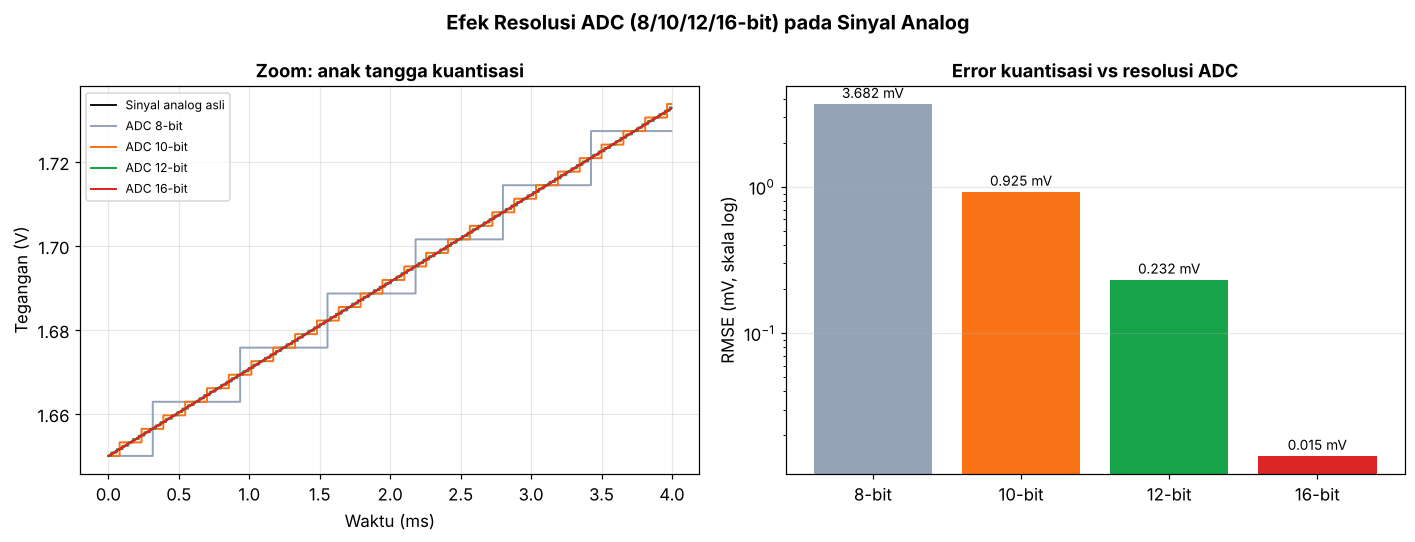

In [ ]:
# Visualisasi: zoom pada 4 ms pertama (tanjakan sinyal paling curam) + RMSE vs resolusi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
m = t <= 0.004
ax1.plot(t[m] * 1000, sinyal_asli[m], 'k', linewidth=1.2, label='Sinyal analog asli')
for bit, c in zip(resolusi_list, ['#94a3b8', '#f97316', '#16a34a', '#dc2626']):
    ax1.step(t[m] * 1000, hasil_adc[bit][m], where='post', color=c, linewidth=1.3, label=f'ADC {bit}-bit')
ax1.set_xlabel('Waktu (ms)'); ax1.set_ylabel('Tegangan (V)')
ax1.set_title('Zoom: anak tangga kuantisasi', fontsize=12, fontweight='bold')
ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

bars = ax2.bar(df_adc['Resolusi'], df_adc['RMSE (mV)'], color=['#94a3b8', '#f97316', '#16a34a', '#dc2626'])
ax2.set_yscale('log')
for bar, v in zip(bars, df_adc['RMSE (mV)']):
    ax2.annotate(f'{v:.3f} mV', (bar.get_x() + bar.get_width() / 2, v), textcoords='offset points',
                 xytext=(0, 4), ha='center', fontsize=9)
ax2.set_ylabel('RMSE (mV, skala log)')
ax2.set_title('Error kuantisasi vs resolusi ADC', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
plt.suptitle('Efek Resolusi ADC (8/10/12/16-bit) pada Sinyal Analog', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
# Kasus nyata: sensor suhu LM35 (10 mV per derajat C) dibaca ADC dengan Vref 3.3 V
np.random.seed(1)
n = 20000
waktu = np.arange(n)
suhu_asli = 27 + 3 * np.sin(waktu / 15)               # suhu sebenarnya (tren dari Hands-On 2)
suhu_sensor = suhu_asli + np.random.normal(0, 0.8, n) # + noise sensor sigma 0.8 C
sensitivitas = 0.010                                  # LM35: 10 mV/C
v_sensor = suhu_sensor * sensitivitas

rmse = lambda a: float(np.sqrt(np.mean(a ** 2)))
err_noise = rmse(suhu_sensor - suhu_asli)

baris = []
for bit in resolusi_list:
    vq, langkah = kuantisasi_adc(v_sensor, bit)
    suhu_baca = vq / sensitivitas
    baris.append({
        'Resolusi': f'{bit}-bit',
        'Resolusi suhu (C/LSB)': round(langkah / sensitivitas, 4),
        'Error kuantisasi (C)': round(rmse(suhu_baca - suhu_sensor), 4),
        'Error total vs suhu asli (C)': round(rmse(suhu_baca - suhu_asli), 4),
    })
df_suhu = pd.DataFrame(baris)
print(f"Error akibat noise sensor saja: {err_noise:.4f} C\n")
print(df_suhu.to_string(index=False))

e12 = df_suhu.loc[2, 'Error total vs suhu asli (C)']
e16 = df_suhu.loc[3, 'Error total vs suhu asli (C)']
print(f"\nError total 12-bit = {e12:.4f} C, 16-bit = {e16:.4f} C -> perbaikan hanya {(e12 - e16) / e12 * 100:.2f}%")

# Rentang ADC yang terpakai untuk suhu 20-40 C
v_min, v_max = 20 * sensitivitas, 40 * sensitivitas
print(f"Suhu 20-40 C = {v_min:.2f}-{v_max:.2f} V -> hanya {(v_max - v_min) / 3.3 * 100:.1f}% dari rentang 0-3.3 V yang terpakai")
print(f"Jumlah level efektif 12-bit pada rentang itu: {(v_max - v_min) / (3.3 / 2**12):.0f} dari 4096")

Error akibat noise sensor saja: 0.8000 C

Resolusi  Resolusi suhu (C/LSB)  Error kuantisasi (C)  Error total vs suhu asli (C)
   8-bit                 1.2891                0.3701                        0.8820
  10-bit                 0.3223                0.0935                        0.8054
  12-bit                 0.0806                0.0233                        0.8005
  16-bit                 0.0050                0.0015                        0.8000

Error total 12-bit = 0.8005 C, 16-bit = 0.8000 C -> perbaikan hanya 0.06%
Suhu 20-40 C = 0.20-0.40 V -> hanya 6.1% dari rentang 0-3.3 V yang terpakai
Jumlah level efektif 12-bit pada rentang itu: 248 dari 4096


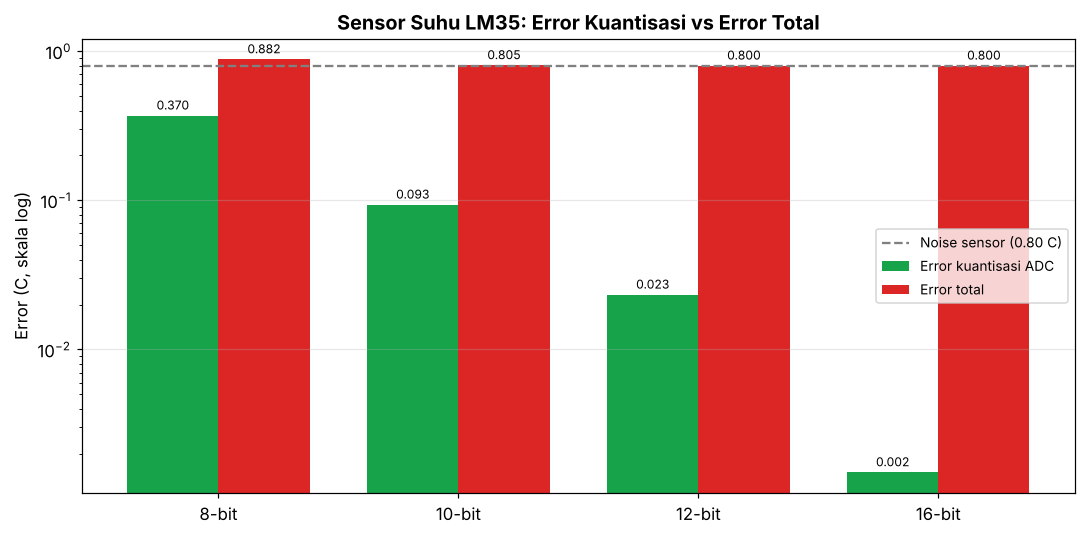

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_suhu)); lebar = 0.38
b1 = ax.bar(x - lebar/2, df_suhu['Error kuantisasi (C)'], lebar, color='#16a34a', label='Error kuantisasi ADC')
b2 = ax.bar(x + lebar/2, df_suhu['Error total vs suhu asli (C)'], lebar, color='#dc2626', label='Error total')
ax.axhline(err_noise, color='gray', linestyle='--', label=f'Noise sensor ({err_noise:.2f} C)')
for bars in (b1, b2):
    for bar in bars:
        ax.annotate(f'{bar.get_height():.3f}', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    textcoords='offset points', xytext=(0, 4), ha='center', fontsize=8)
ax.set_yscale('log'); ax.set_xticks(x); ax.set_xticklabels(df_suhu['Resolusi'])
ax.set_ylabel('Error (C, skala log)')
ax.set_title('Sensor Suhu LM35: Error Kuantisasi vs Error Total', fontsize=13, fontweight='bold')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

### Analisis Soal 2

**Hasil simulasi ADC (Vref 3.3 V):**

| Resolusi | Langkah | RMSE kuantisasi |
|---|---|---|
| 8-bit | 12.89 mV | 3.68 mV |
| 10-bit | 3.22 mV | 0.93 mV |
| 12-bit | 0.81 mV | 0.23 mV |
| **16-bit** | **0.05 mV** | **0.0145 mV** |

Dari 12-bit ke 16-bit, error kuantisasi turun **16 kali** (2^4), sesuai teori `RMSE = LSB / sqrt(12)`. Secara angka itu peningkatan yang besar.

**Pada sensor suhu LM35 (10 mV/°C):**
- Resolusi pembacaan membaik dari **0.081 °C/LSB (12-bit)** menjadi **0.005 °C/LSB (16-bit)**.
- Namun **error total** hampir tidak berubah: **0.8005 °C (12-bit) vs 0.8000 °C (16-bit)**, perbaikan hanya sekitar **0.06%**.
- Penyebabnya, error kuantisasi 12-bit (0.023 °C) sudah sekitar 34 kali lebih kecil daripada noise sensor (0.8 °C). Error independen dijumlahkan secara kuadrat, sehingga noise sensor mendominasi dan menyembunyikan peningkatan resolusi ADC. Akurasi LM35 sendiri juga hanya pada orde ±0.5 °C (lihat datasheet), jauh lebih kasar dari 0.081 °C.
- Ada satu hal yang menarik: suhu 20-40 °C hanya menghasilkan 0.2-0.4 V, yaitu 6.1% dari rentang 0-3.3 V. ADC 12-bit hanya memakai sekitar **248 dari 4096 level**, sedangkan 16-bit memakai sekitar 3.970 level. Jadi 16-bit memang memperbaiki *level yang terpakai*, tetapi itu tidak berguna selama noise sensor masih jauh lebih besar.

**Trade-off 16-bit:** harga dan arus lebih besar, waktu konversi lebih lama, data lebih besar, dan ADC internal ESP32 hanya 12-bit sehingga perlu ADC eksternal (mis. via I2C). Untuk menurunkan noise pada sensor suhu, cara yang lebih murah adalah *averaging/oversampling* atau moving average seperti Hands-On 2.

3. Pada Hands-On 6, hitung ulang estimasi umur baterai jika interval kirim data diperpendek menjadi tiap 1 menit (bukan 5 menit). Jelaskan trade-off yang terjadi antara responsivitas monitoring dan umur baterai.

In [ ]:
tahap_aktif = [
    {'nama': 'Wake-up + Baca Sensor', 'arus_mA': 30,  'durasi_detik': 0.05},
    {'nama': 'Koneksi WiFi',          'arus_mA': 120, 'durasi_detik': 2.5},
    {'nama': 'Kirim Data (MQTT)',     'arus_mA': 160, 'durasi_detik': 0.3},
]
ARUS_DEEP_SLEEP_mA = 0.01
KAPASITAS_mAh = 2000
durasi_aktif = sum(s['durasi_detik'] for s in tahap_aktif)

def buat_tahapan(interval_detik, durasi_wifi=None):
    """Tahapan 1 siklus: tahap aktif + deep sleep sebagai sisa interval."""
    tahap = [dict(s) for s in tahap_aktif]
    if durasi_wifi is not None:
        tahap[1]['durasi_detik'] = durasi_wifi
    aktif = sum(s['durasi_detik'] for s in tahap)
    tahap.append({'nama': 'Deep Sleep', 'arus_mA': ARUS_DEEP_SLEEP_mA,
                  'durasi_detik': round(interval_detik - aktif, 4)})
    df = pd.DataFrame(tahap)
    df['Muatan (mAh)'] = df['arus_mA'] * df['durasi_detik'] / 3600
    return df

def estimasi_baterai(interval_detik, **kw):
    df = buat_tahapan(interval_detik, **kw)
    muatan_siklus = df['Muatan (mAh)'].sum()
    siklus_per_hari = 86400 / interval_detik
    konsumsi_harian = siklus_per_hari * muatan_siklus
    umur_hari = KAPASITAS_mAh / konsumsi_harian
    return df, {'interval_detik': interval_detik, 'muatan_siklus_mAh': muatan_siklus,
                'siklus_per_hari': siklus_per_hari, 'konsumsi_harian_mAh': konsumsi_harian,
                'umur_hari': umur_hari}

# Validasi: harus sama dengan output Hands-On 6 untuk interval 5 menit
_, v = estimasi_baterai(300)
print(f"Validasi 5 menit -> muatan/siklus {v['muatan_siklus_mAh']:.6f} mAh, "
      f"{v['konsumsi_harian_mAh']:.2f} mAh/hari, umur {v['umur_hari']:.0f} hari (modul: 0.097909 mAh, 28.20 mAh/hari, 71 hari)")

Validasi 5 menit -> muatan/siklus 0.097909 mAh, 28.20 mAh/hari, umur 71 hari (modul: 0.097909 mAh, 28.20 mAh/hari, 71 hari)


In [ ]:
# Perbandingan interval 5 menit vs 1 menit
df5, r5 = estimasi_baterai(300)
df1, r1 = estimasi_baterai(60)

print("=== INTERVAL 1 MENIT: rincian tahapan per siklus ===")
print(df1.to_string(index=False))
print()

banding = pd.DataFrame({
    'Interval 5 menit': r5, 'Interval 1 menit': r1}).T.drop(columns='interval_detik')
banding.columns = ['Muatan/siklus (mAh)', 'Siklus/hari', 'Konsumsi/hari (mAh)', 'Umur baterai (hari)']
print(banding.round(4).to_string())
print()
print(f"Interval 1 menit: durasi 1 siklus {r1['interval_detik']} detik, {r1['siklus_per_hari']:.0f} siklus/hari")
print(f"Konsumsi energi per hari : {r1['konsumsi_harian_mAh']:.2f} mAh (5 menit: {r5['konsumsi_harian_mAh']:.2f} mAh)")
print(f"Estimasi umur baterai 2000 mAh : {r1['umur_hari']:.1f} hari (~{r1['umur_hari']/30:.1f} bulan)")
print(f"Umur baterai turun {r5['umur_hari'] / r1['umur_hari']:.2f}x dibanding interval 5 menit")
print(f"Pembacaan data naik {r1['siklus_per_hari'] / r5['siklus_per_hari']:.0f}x (288 -> 1440 data per hari)")

# Kontribusi energi per hari tiap tahap
for nama, df, r in [('5 menit', df5, r5), ('1 menit', df1, r1)]:
    persen = df.set_index('nama')['Muatan (mAh)'] / df['Muatan (mAh)'].sum() * 100
    print(f"\nKontribusi energi per tahap (interval {nama}):")
    print(persen.round(2).to_string())

=== INTERVAL 1 MENIT: rincian tahapan per siklus ===
                 nama  arus_mA  durasi_detik  Muatan (mAh)
Wake-up + Baca Sensor    30.00          0.05      0.000417
         Koneksi WiFi   120.00          2.50      0.083333
    Kirim Data (MQTT)   160.00          0.30      0.013333
           Deep Sleep     0.01         57.15      0.000159

                  Muatan/siklus (mAh)  Siklus/hari  Konsumsi/hari (mAh)  Umur baterai (hari)
Interval 5 menit               0.0979        288.0              28.1977              70.9277
Interval 1 menit               0.0972       1440.0             140.0286              14.2828

Interval 1 menit: durasi 1 siklus 60 detik, 1440 siklus/hari
Konsumsi energi per hari : 140.03 mAh (5 menit: 28.20 mAh)
Estimasi umur baterai 2000 mAh : 14.3 hari (~0.5 bulan)
Umur baterai turun 4.97x dibanding interval 5 menit
Pembacaan data naik 5x (288 -> 1440 data per hari)

Kontribusi energi per tahap (interval 5 menit):
nama
Wake-up + Baca Sensor     0.43
Koneksi

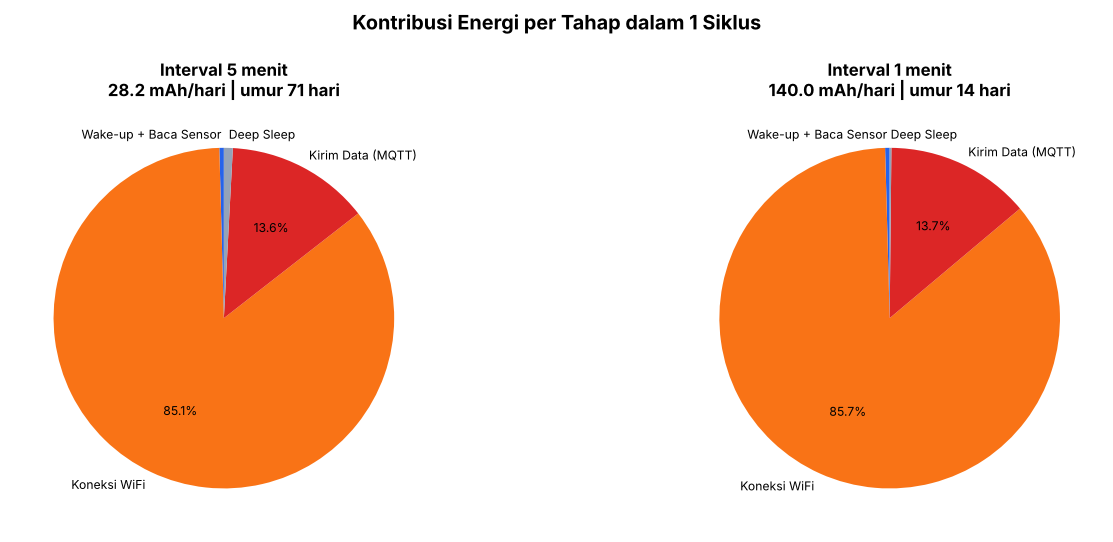

In [ ]:
# Visualisasi: kontribusi energi tiap tahap (interval 5 menit vs 1 menit)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
warna = ['#2563eb', '#f97316', '#dc2626', '#94a3b8']
for ax, (judul, df, r) in zip(axes, [('Interval 5 menit', df5, r5), ('Interval 1 menit', df1, r1)]):
    ax.pie(df['Muatan (mAh)'], labels=df['nama'], autopct=lambda p: f'{p:.1f}%' if p > 3 else '', colors=warna, startangle=90,
           textprops={'fontsize': 8}, labeldistance=1.08)
    ax.set_title(f"{judul}\n{r['konsumsi_harian_mAh']:.1f} mAh/hari | umur {r['umur_hari']:.0f} hari",
                 fontsize=11, fontweight='bold')
plt.suptitle('Kontribusi Energi per Tahap dalam 1 Siklus', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

Interval  Data per hari  Penundaan deteksi maks (detik)  Umur baterai (hari)
    10 s           8640                              10                  2.4
    30 s           2880                              30                  7.1
 1 menit           1440                              60                 14.3
 2 menit            720                             120                 28.5
 5 menit            288                             300                 70.9
10 menit            144                             600                140.7
15 menit             96                             900                209.2
30 menit             48                            1800                408.2
60 menit             24                            3600                778.3


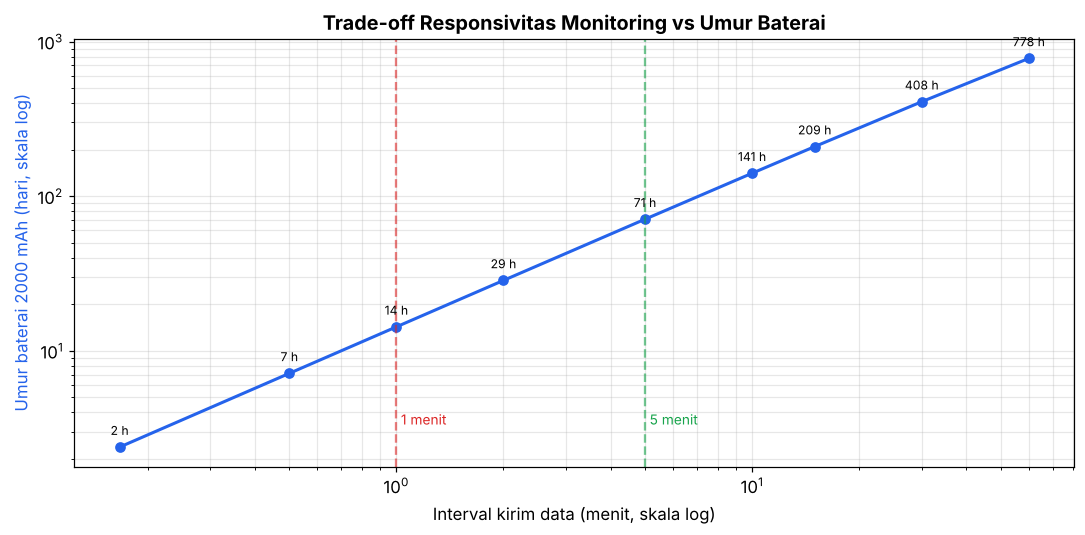

In [ ]:
# Analisis trade-off: umur baterai vs interval kirim (responsivitas)
intervals = np.array([10, 30, 60, 120, 300, 600, 900, 1800, 3600])
umur = np.array([estimasi_baterai(i)[1]['umur_hari'] for i in intervals])
df_tr = pd.DataFrame({
    'Interval': [f'{i} s' if i < 60 else f'{i // 60} menit' for i in intervals],
    'Data per hari': (86400 / intervals).round(0).astype(int),
    'Penundaan deteksi maks (detik)': intervals,
    'Umur baterai (hari)': umur.round(1),
})
print(df_tr.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(intervals / 60, umur, 'o-', color='#2563eb', linewidth=2)
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xlabel('Interval kirim data (menit, skala log)')
ax1.set_ylabel('Umur baterai 2000 mAh (hari, skala log)', color='#2563eb')
for i, u in zip(intervals, umur):
    ax1.annotate(f'{u:.0f} h', (i / 60, u), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
for i, c in [(60, '#dc2626'), (300, '#16a34a')]:
    ax1.axvline(i / 60, color=c, linestyle='--', alpha=0.6)
ax1.text(1.03, umur.min() * 1.4, '1 menit', color='#dc2626', fontsize=9)
ax1.text(5.15, umur.min() * 1.4, '5 menit', color='#16a34a', fontsize=9)
ax1.set_title('Trade-off Responsivitas Monitoring vs Umur Baterai', fontsize=13, fontweight='bold')
ax1.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

In [ ]:
# Skenario tambahan: dampak optimasi durasi koneksi WiFi pada interval 1 menit
# (mis. WiFi static IP / fast reconnect memangkas koneksi dari 2.5 s menjadi 1.0 s)
for durasi_wifi in [5.0, 2.5, 1.0]:
    _, r = estimasi_baterai(60, durasi_wifi=durasi_wifi)
    print(f"Interval 1 menit, koneksi WiFi {durasi_wifi:>3} s -> {r['konsumsi_harian_mAh']:6.1f} mAh/hari, umur {r['umur_hari']:5.1f} hari")

Interval 1 menit, koneksi WiFi 5.0 s ->  260.0 mAh/hari, umur   7.7 hari
Interval 1 menit, koneksi WiFi 2.5 s ->  140.0 mAh/hari, umur  14.3 hari
Interval 1 menit, koneksi WiFi 1.0 s ->   68.0 mAh/hari, umur  29.4 hari


### Analisis Soal 3

**Hasil perhitungan (baterai 2000 mAh, durasi dan arus tahap aktif tetap):**

| Parameter | Interval 5 menit | Interval 1 menit |
|---|---|---|
| Durasi deep sleep | 297.15 s | 57.15 s |
| Muatan per siklus | 0.0979 mAh | 0.0972 mAh |
| Siklus per hari | 288 | 1440 |
| Konsumsi per hari | 28.20 mAh | 140.03 mAh |
| **Umur baterai** | **70.9 hari (~2.4 bulan)** | **14.3 hari (~0.5 bulan)** |

Perhitungan 1 menit: muatan per siklus = 0.000417 + 0.083333 + 0.013333 + 0.000159 = 0.0972 mAh, lalu 0.0972 × 1440 = 140.03 mAh/hari, sehingga umur = 2000 / 140.03 = **14.3 hari**.

**Mengapa umur turun hampir tepat 5 kali (4.97x):** energi per siklus hampir tidak berubah karena 98-99% energi dipakai oleh tahap koneksi WiFi dan pengiriman MQTT, sedangkan deep sleep hanya menyumbang 0.16% (1 menit) dan 0.84% (5 menit). Memperpendek interval hanya mempertinggi *jumlah siklus*, sehingga konsumsi harian hampir sebanding dengan jumlah siklus dan umur baterai berbanding terbalik dengan frekuensi pengiriman.

**Trade-off responsivitas vs umur baterai:**
- **Interval pendek (1 menit):** 1440 data/hari dan penundaan deteksi perubahan maksimal 1 menit, tetapi baterai hanya bertahan sekitar 2 minggu. Cocok jika ada catu daya tetap atau pemantauan kritis.
- **Interval panjang (5 menit atau lebih):** baterai lebih awet (71 hari pada 5 menit, sekitar 140 hari pada 10 menit), tetapi kejadian singkat di antara dua pengiriman bisa terlewat dan deteksi perubahan tertunda hingga satu interval.
- Hubungannya hampir linear di skala log (lihat grafik): menggandakan interval hampir menggandakan umur baterai.



